## The Problem
    When I walk in to a clothing store, it feels good not spending time on searching for a t-shirt in a pile of unorganized clothes. Every aspect of clothing has it's own designated space in the limited area of store and a person or two responsible for the keeping of clothes(dubbed, The Clothe Keeper).
    
    Now physical stores have a younger sister, online store. Being a millenial she is the cause of a huge problem; a couple of people are enough to sort the clothes at a physical store since the stock is limited and everyone knows their section perfectly but, on an online store the products are figuratively innumerous (atleast for a human) and hence the categorization is a huge problem. 
    
    However, to solve the millennial problem a millennial serves the best. Hence we take upon ourselves the task of classifying "figuratively innumerous" products with descriptions into their actual shelves using the best tools at our disposal - The Data Scientist toolkit - specifically Machine learning and NLP.
    

### Load data

    The battle begins: We are given 2 files, one tagged by humans manually and the other by a computer both in json format. Let's read them to a dataframe and save as csv for easier processing the next time around

In [2]:
import pandas as pd


#this is the machine tagged data
catalogue = pd.read_json('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/mani-work/catalog-data/text_with_machine.json',lines=True)
#mh is the manual human tagged data
catalogue_mh = pd.read_json('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/mani-work/catalog-data/text_dump_with_mh.json',lines=True)
catalogue_mh.head()

,product_id,root_node,title,shelf,outlier,item_id,short_description,long_description,all_shelves
0,642E2J75K4EE,Clothing,Men's Performance Penn State University Gridlo...,Clothing/Men/Men's Activewear,1.0,155051843,<b>Men's Performance Penn State University Gri...,<b>Men's Performance Penn State University Gri...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
1,36HSVAC1S3P1,Clothing,Faded Glory Men's Fleece Lined Flannel,Clothing/Men/Men's Jackets & Outerwear,1.0,45466849,This Faded Glory Men's Fleece Lined Flannel is...,<BR><B>Faded Glory Men's Fleece Lined Flannel<...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
2,58EH09O2BBCY,Clothing,Hanes Mens Premium Beefy-T Cotton Long Sleeve ...,Clothing/Men/Men's Activewear,1.0,14710841,If you love our famous Beefy-T tee (and everyb...,<b>Hanes Mens Premium Beefy-T Cotton Long Slee...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
3,157YUJ985OVJ,Clothing,219 Wicking Color Block Jersey - Youth GOLD/WH...,Clothing/Men/Men's Activewear,1.0,171359926,100% polyester wicking knit with 93% polyester...,100% polyester wicking knit with 93% polyester...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
4,4QL7H4GISSG1,Clothing,Nike Men's Dri-Fit Tech Vent Stripe Golf Polo ...,Clothing/Men/Men's Activewear,1.0,184542132,<b>Nike Men's Dri-Fit Tech Vent Stripe Golf Po...,<b>Nike Men's Dri-Fit Tech Vent Stripe Golf Po...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."


#### saving the files as csv
    catalogue.to_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/catalog-data/catalog-data/catalogue_machine_tagged.csv')
    catalogue_mh.to_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/catalog-data/catalog-data/catalogue_human_tagged.csv')

    It is always a good idea to not work on the actual data directly, let's create a copy and go ahead with it. What happens if I work with the original source directly? What happens if I don't?

    We can use either of the methods, it isn't set-in-stone to use one. If the data is decent and our machine can handle it we can make a copy otherwise we don't, the only downside of not having a copy however is once we transform or delete a part of it we won't be able to role back to the original state and hence have to start from loading the data again.

In [3]:
catalogue_copy = catalogue_mh.copy(deep=True)
#if ids are not same then the deep copy is successful in creating a new object altogether
print(id(catalogue_mh) == id(catalogue_copy))

False


# Importing Libraries

In [7]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import missingno
from tqdm.notebook import tqdm
tqdm.pandas()

import re
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import wordcloud


from nltk import wordnet as wn
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from nltk import pos_tag
from nltk import ngrams
from collections import Counter
from sklearn.preprocessing import MinMaxScaler

import gensim.models.keyedvectors as word2vec
wv = word2vec.KeyedVectors.load_word2vec_format("/Users/gurumanikanta/Documents/DS-Analytics/GoogleNews-vectors-negative300.bin.gz",binary=True)
from scipy.spatial.distance import cosine


from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score  

### Data Firstlook

In [8]:
#we will work with catalogue_copy dataframe from now on
catalogue_copy.info()
#looks like a few null values exist

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56398 entries, 0 to 56397
Data columns (total 9 columns):
product_id           56398 non-null object
root_node            53431 non-null object
title                56398 non-null object
shelf                53431 non-null object
outlier              53431 non-null float64
item_id              56398 non-null int64
short_description    56398 non-null object
long_description     56398 non-null object
all_shelves          56398 non-null object
dtypes: float64(1), int64(1), object(7)
memory usage: 3.9+ MB


In [9]:
catalogue_copy.isna().sum()
#only root_node, shelf, and outlier columns have missing values 

product_id              0
root_node            2967
title                   0
shelf                2967
outlier              2967
item_id                 0
short_description       0
long_description        0
all_shelves             0
dtype: int64

    Insight from the above numbers? or assumptions?

    When I see same number of null values in all the columns with null, I get a feeling all of them are at the same indices, that's my assumption and hence I'm obliged to prove it's factfulness.

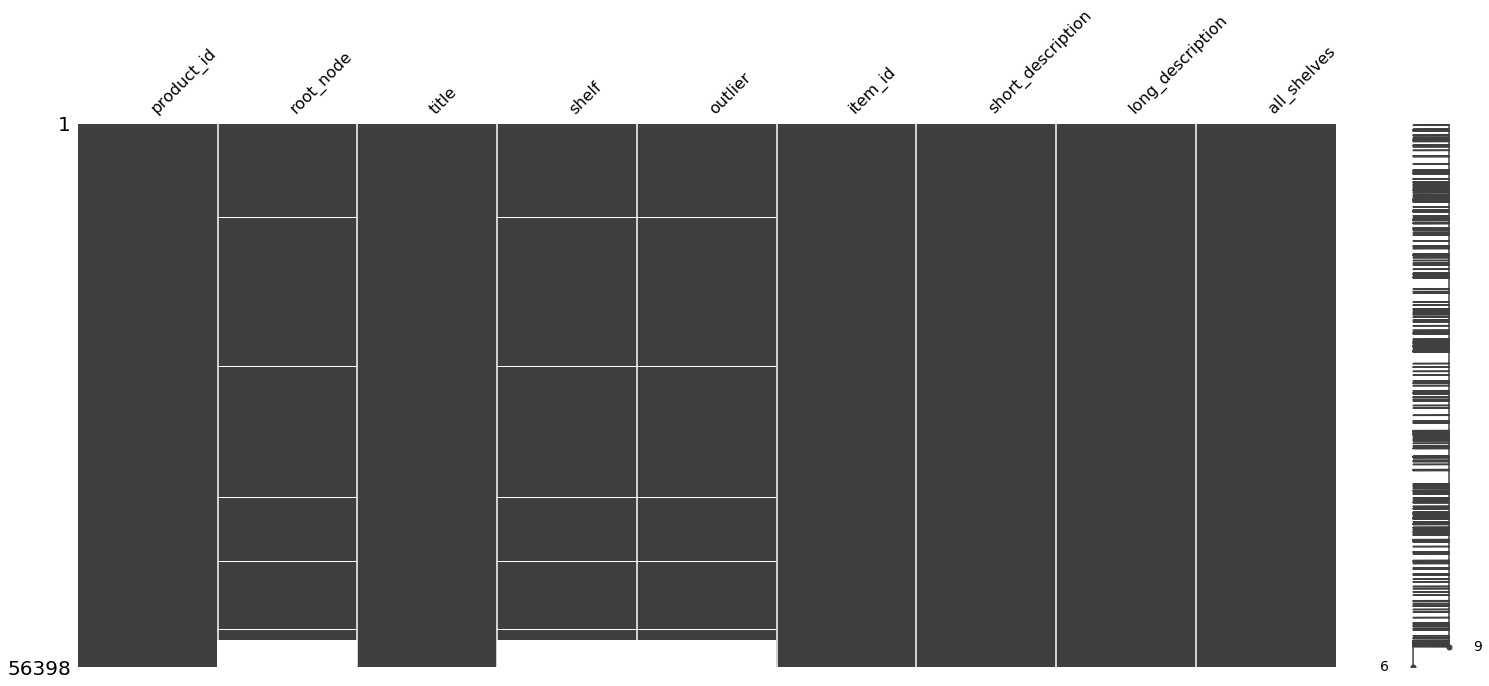

In [10]:
missingno.matrix(catalogue_copy)
#looks like missing values in all columns are at same indeces

    Does it look like it yet? pretty much, right? I would still prefer to get a solid yes/no for my question based on index matching

In [11]:
print('root_node vs shelf: ',np.array_equal(np.where(catalogue_copy['root_node'].isna()), np.where(catalogue_copy['shelf'].isna())))
print('root_node vs outlier: ',np.array_equal(np.where(catalogue_copy['root_node'].isna()), np.where(catalogue_copy['outlier'].isna())))

root_node vs shelf:  True
root_node vs outlier:  True


Now that we know the missing values are at the same indeces, there are a few choices to proceed:
    1. Remove all rows with missing values
    2. Impute based on rows above/ below or even based on other columns
    3. Understand what the columns mean and decide if imputing works
    
So, to take the next step let's understand what each of these columns mean:


    product_id              Unique identifier for each row
    root_node               Category of the product
    title                   Title for the product
    shelf                   Primary Location where the product has to reside
    outlier                 1 is the actual category(root_node) 2 is outlier
    item_id                 Another Unique identifier for each row
    short_description       Short description of product
    long_description        Detailed description of product
    all_shelves             All possible locations where the product could reside

In [12]:
tqdm.pandas()
is_same = lambda val: val['shelf'] == val['all_shelves'][0]['shelf']
sum(catalogue_copy.loc[np.where(catalogue_copy['shelf'].notna())[0],:].progress_apply(is_same,axis=1))

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/tqdm/std.py:658: FutureWarning: The Panel class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version
  from pandas import Panel


40878

    Did you get what was happening above? I knew you would... anyway below was what I intended to do

    Check if the first shelf from all_shelves can be used to impute nulls in shelf field
    is_same has True/False depending on the match between shelf and first shelf from all shelves. If the sum of is_same equals total non-null values in shelf: 53431 we could directly have used the first shelf from all shelves field to fill in the missing values

In [13]:
catalogue_copy.loc[np.where(catalogue_copy['shelf'].notna())[0],'first_shelf?'] = catalogue_copy.loc[np.where(catalogue_copy['shelf'].notna())[0],:].progress_apply(is_same,axis=1)
catalogue_copy.loc[np.where(catalogue_copy['first_shelf?']==False)[0],['title','shelf','all_shelves']]

,title,shelf,all_shelves
1,Faded Glory Men's Fleece Lined Flannel,Clothing/Men/Men's Jackets & Outerwear,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
7,Russell Men's Solid Performance Active Tank,Clothing/Young Men's Styles,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
10,And 1 Men's Sunrise Player Pull Over Hoodie,Clothing/Young Men's Styles,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
12,Fruit of the Loom Men's Fleece Full Zip Hood,Clothing/Men/Men's Activewear,[{'shelf': 'Clothing/Men/Men's Sweaters & Hood...
18,Russell Mens Performance Knit Pant,Clothing/Men/Men's Bottoms/Men's Pants,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
...,...,...,...
54185,CafePress Men's World's Most Awesome Grandpa S...,Clothing/Men/Men's Sweaters & Hoodies,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
54186,Men's Printed Aztec Fleece Jacket with Sherpa ...,Clothing/Men/Men's Sweaters & Hoodies,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
54187,Starter Men's Winter Full Zip Fleece Jacket,Clothing/Men/Men's Sweaters & Hoodies,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."
54188,Hanes Men's Nano Premium Soft Lightweight Flee...,Clothing/Men/Men's Sweaters & Hoodies,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v..."


    Looks like we can't directly assign a shelf from position 0 of all_shelves.
    On the flip side, it doesn't seem like a good idea to use 'shelf'/'outlier' to classify products because without knowing the proper root a shelf can't be assigned accurately and assigning the proper root itself is our target.

(-0.5, 1499.5, 699.5, -0.5)

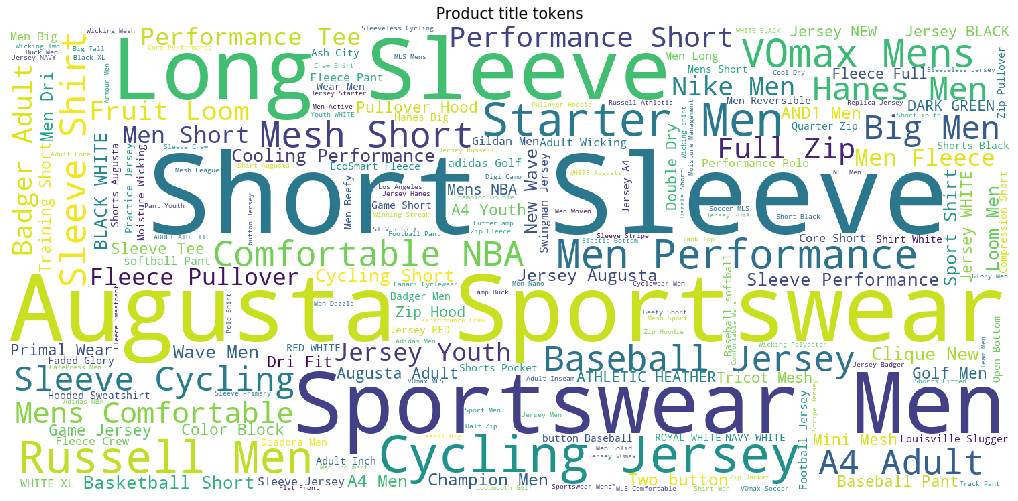

In [21]:
wc = wordcloud.WordCloud(width=1500,height=700,background_color='white',contour_color='white')
plt.figure(figsize=(18,12),edgecolor='white')
plt.title('Product title tokens',fontsize=15)
plt.imshow(wc.generate(' '.join(catalogue_copy['title'].values)))
plt.xticks([])
plt.yticks([])
plt.axis('off')

    Looks like most products belong to clothing segement

In [15]:
pd.value_counts(catalogue_copy['short_description'])

<p>Cutter &amp; Buck's mission is to provide our customers with seamless transitions between working days, busy weekends, playtime, and nighttime. We personally review all applications and specifically look for websites that are consistent with our branding and marketing objectives.</p>                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              706
</p>                                                                                                                                                                                                   

In [16]:
pd.value_counts(catalogue_copy['long_description'])

</p>                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                751
</P>                                                                                                                                                                                                                                                                                                            

    What steps can we take to clean the above data?

    From the above value_counts it is clear that all products do not have unique description. Spending a little time going through them also proves that some descriptions might readily not seem like it's for clothes.
    
    There are also html tags in the descriptions, let's remove all the tags from descriptions

In [22]:
rem_tags = lambda text: re.sub('(<.*?>)',' ',text)

catalogue_copy['short_description'] = catalogue_copy['short_description'].progress_apply(rem_tags)
catalogue_copy['long_description'] = catalogue_copy['long_description'].progress_apply(rem_tags)

print('short: {}\nlong: {}'.format(sum(catalogue_copy['short_description']==' '),sum(catalogue_copy['long_description']==' ')))

catalogue_copy['short_description'].replace('short description is not available',' ',inplace=True)
catalogue_copy['long_description'].replace('long description is not available',' ',inplace=True)

#All rows without descriptions will now have space so we don't have to worry about treating null values


short: 671
long: 1282


    After replacling all tags with spaces, we have many cells containing only space and there are also cells that say no description, so we've also replaced them with space to have only spaces for missing values
    

(-0.5, 1499.5, 699.5, -0.5)

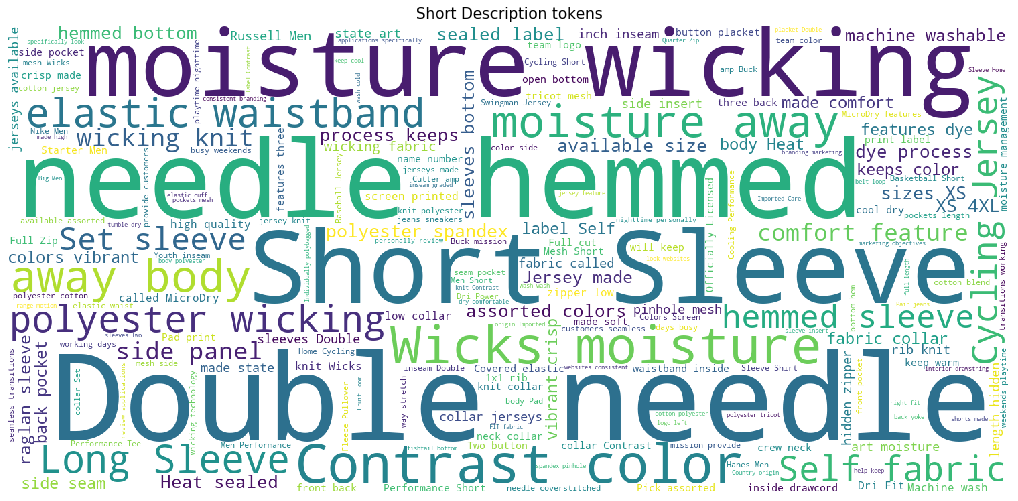

In [23]:
plt.figure(figsize=(18,12),edgecolor='white')
plt.title('Short Description tokens',fontsize=15)
not_space_ind = np.where(catalogue_copy['short_description']!=' ')[0]
plt.imshow(wc.generate(' '.join(catalogue_copy['short_description'][not_space_ind].values)))
plt.xticks([])
plt.yticks([])
plt.axis('off')

(-0.5, 1499.5, 699.5, -0.5)

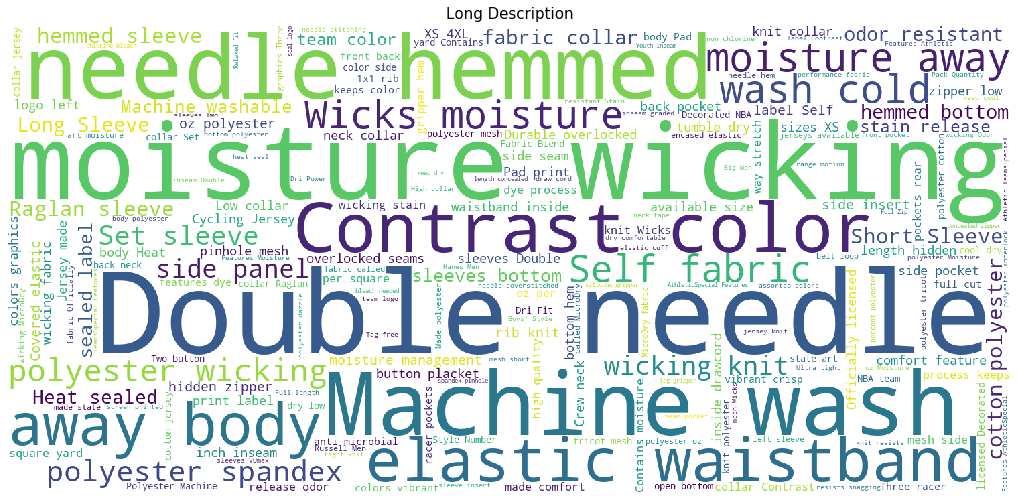

In [25]:
plt.figure(figsize=(18,12),edgecolor='white')
plt.title('Long Description',fontsize=15)
not_space_ind = np.where(catalogue_copy['long_description']!=' ')[0]
plt.imshow(wc.generate(' '.join(catalogue_copy['long_description'][not_space_ind].values)))
plt.xticks([])
plt.yticks([])
plt.axis('off')

    The wordclouds for short and long descriptions do not show any obvious hints(products not related to apparel) for classification. However, they actually have words that aren't related to clothing directly but to the process of manifacturing/maintaining clothes
    

In [20]:
catalogue_copy[catalogue_copy['outlier']==2]

,product_id,root_node,title,shelf,outlier,item_id,short_description,long_description,all_shelves,first_shelf?
141,5CJDPS7XLCT1,Clothing,Tokyo Ghoul Men's Ghoul Masks Anime Wristband,Clothing/Men/Men's Activewear,2.0,140946889,Tokyo Ghoul Men's Ghoul Masks Anime Wristband...,Tokyo Ghoul Men's Ghoul Masks Anime Wristban...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True
249,6HCB76DKDFON,Clothing,Gem Sports Neon Lime Volleyball Spandex - Subl...,Clothing/Men/Men's Activewear,2.0,48467660,Gem Sports Neon Lime Volleyball Spandex - Subl...,Top Quality Product.,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True
450,16KD1FIBVR4D,Clothing,Russell Big Men's Performance Eco Tee,Clothing/Big & Tall/Big & Tall Tops & T-Shirts...,2.0,42437144,Eco fabric made with Repreve recycled fiber ...,"Russell Big Men's Eco Tee : 95% Polyester, ...","[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",False
655,587B3ZXLCUSX,Clothing,Fate/Zero Men's Kiritsugu Command Seal Anime ...,Clothing/Men/Men's Activewear,2.0,187859426,Fate/Zero Men's Kiritsugu Command Seal Anime ...,Fate/Zero Men's Kiritsugu Command Seal Anime...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True
1065,19M7WNR43HSK,Clothing,San Jose Sharks Full Size Removable Face Jerse...,Clothing/Men/Men's Activewear,2.0,142772325,The Removable Face Jersey Display is the newes...,The Removable Face Jersey Display is the newes...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True
...,...,...,...,...,...,...,...,...,...,...
52305,4OH3DI00VOBL,Clothing,Faded Glory - Men's Mock Quarter-Zip Sweatshirt,Clothing/Men/Men's Jackets & Outerwear,2.0,14159419,Long sleeves Quarter zip at neck Kangaroo po...,,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",False
52327,4DIDIPANS6TX,Clothing,Ben Hogan Men's Long Sleeve Performance 1/4 Zi...,Clothing/Men/Men's Jackets & Outerwear,2.0,41136611,Tackle any type of climate with the diverse se...,Tech Quarter Zip Fleece with Mock Neck Made ...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",False
52696,6317TFE4XNOK,Clothing,Duofold by Champion Varitherm Women's Base-Lay...,Clothing/Men/Men's Activewear,2.0,113377255,Long-sleeve thermal top with princess seaming ...,Long-sleeve thermal top with princess seaming ...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True
52854,6OX9FUCOVEIS,Clothing,Starter Men's Full Zip Fleece,Clothing/Men/Men's Jackets & Outerwear,2.0,43935834,You'll keep perfectly warm when you wear this ...,100% Polyester Machine Wash Cold Starter Ful...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",False


    I do not see any obvious difference between outlier 1 and 2. How do we proceed forward now?

    I am probably missing the whole picture but, one way to go about it is try using a clustering algorithm and see if it can identify any differences

# Cleaning and Preprocessing

In [26]:
def penn_to_wn(tag):
    #Convert between the PennTreebank tags to simple Wordnet tags
    if tag.startswith('J'):
        return wn.wordnet.ADJ
    elif tag.startswith('N'):
        return wn.wordnet.NOUN
    elif tag.startswith('R'):
        return wn.wordnet.ADV
    elif tag.startswith('V'):
        return wn.wordnet.VERB
    return None


englishStopWords = stopwords.words('english')
lemmatizer = WordNetLemmatizer()
def clean_lemmatize_content(text):
    '''Lemmatizes text considering pos_tag, removes punctuations and returns lower case text'''
    try:
        clean_lemmatized = list()
        text = re.sub('(<.*?>)',' ',text)
        text = re.sub('[0-9]+',' ',text)
        text = re.sub('\W+',' ',text)
        for word,tag in pos_tag(text.split()):
            if word not in englishStopWords:
                wn_tag = penn_to_wn(tag)
                try:
                    clean_lemmatized.append(lemmatizer.lemmatize(word,pos=wn_tag))
                except:
                    pass

        return ' '.join(clean_lemmatized).lower()
    except:
        return text

In [27]:
catalogue_copy['clean_title'] = catalogue_copy['title'].progress_apply(clean_lemmatize_content)
catalogue_copy['clean_sh_des'] = catalogue_copy['short_description'].progress_apply(clean_lemmatize_content)
catalogue_copy['clean_long_des'] = catalogue_copy['long_description'].progress_apply(clean_lemmatize_content)

In [28]:
catalogue_copy.head()

,product_id,root_node,title,shelf,outlier,item_id,short_description,long_description,all_shelves,clean_title,clean_sh_des,clean_long_des
0,642E2J75K4EE,Clothing,Men's Performance Penn State University Gridlo...,Clothing/Men/Men's Activewear,1.0,155051843,Men's Performance Penn State University Gridl...,Men's Performance Penn State University Gridl...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",men performance penn state university gridlock...,men performance penn state university gridlock...,men performance penn state university gridlock...
1,36HSVAC1S3P1,Clothing,Faded Glory Men's Fleece Lined Flannel,Clothing/Men/Men's Jackets & Outerwear,1.0,45466849,This Faded Glory Men's Fleece Lined Flannel is...,Faded Glory Men's Fleece Lined Flannel : Sh...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",faded glory men fleece lined flannel,faded glory men fleece lined flannel perfect f...,faded glory men fleece lined flannel shell cot...
2,58EH09O2BBCY,Clothing,Hanes Mens Premium Beefy-T Cotton Long Sleeve ...,Clothing/Men/Men's Activewear,1.0,14710841,If you love our famous Beefy-T tee (and everyb...,Hanes Mens Premium Beefy-T Cotton Long Sleeve...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",hanes mens premium beefy t cotton long sleeve ...,love famous beefy t tee everybody youll want w...,hanes mens premium beefy t cotton long sleeve ...
3,157YUJ985OVJ,Clothing,219 Wicking Color Block Jersey - Youth GOLD/WH...,Clothing/Men/Men's Activewear,1.0,171359926,100% polyester wicking knit with 93% polyester...,100% polyester wicking knit with 93% polyester...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",wicking color block jersey youth gold white s,polyester wicking knit polyester spandex mesh ...,polyester wicking knit polyester spandex mesh ...
4,4QL7H4GISSG1,Clothing,Nike Men's Dri-Fit Tech Vent Stripe Golf Polo ...,Clothing/Men/Men's Activewear,1.0,184542132,Nike Men's Dri-Fit Tech Vent Stripe Golf Polo...,Nike Men's Dri-Fit Tech Vent Stripe Golf Polo...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",men dri fit tech vent stripe golf polo shirt,men dri fit tech vent stripe golf polo shirt r...,men dri fit tech vent stripe golf polo shirt f...


# Vectorization & Clustering    
    Let's try to cluster the products based on title, short and long descriptions
    Initially using countvectorized data with KMeans clustering serves the purpose
    However, since there are words repeated in title, short and long descriptions we will look at the respective vectorizers seperately. This method will also help us understand if any of those features contribute to a cluster the most.

In [29]:
count_vec = CountVectorizer(ngram_range = (1,2),max_features=300)
km = KMeans(n_clusters=2)

#### Title countvectorizer

In [30]:
cv_df = pd.DataFrame(count_vec.fit_transform(catalogue_copy['clean_title'].fillna(' ')).toarray(),columns=count_vec.get_feature_names())
cv_df.head()

,active,adidas,adidas golf,adult,adult inch,adult wicking,all,armour,ash,ash city,...,womens,woven,wristband,xl,xs,xxl,youth,zip,zip hood,zip pullover
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [31]:
pred = km.fit_predict(cv_df)
print(pd.value_counts(pred))
print(np.where(pred==1))

1    29422
0    26976
dtype: int64
(array([    2,     3,     6, ..., 56392, 56394, 56397]),)


#### Short description count vectorizer

In [32]:
cv_df_sd = pd.DataFrame(count_vec.fit_transform(catalogue_copy['clean_sh_des'].fillna(' ')).toarray(),columns=count_vec.get_feature_names())
pred_sd = km.fit_predict(cv_df_sd)

In [33]:
print(pd.value_counts(pred_sd))
print(np.where(pred_sd==1))

0    50908
1     5490
dtype: int64
(array([    3,     6,    28, ..., 56362, 56377, 56387]),)


#### Long description count vectorizer

In [34]:
cv_df_ld = pd.DataFrame(count_vec.fit_transform(catalogue_copy['clean_long_des'].fillna(' ')).toarray(),columns=count_vec.get_feature_names())
pred_ld = km.fit_predict(cv_df_ld)

In [35]:
print(pd.value_counts(pred_ld))
print(np.where(pred_ld==1))

0    54486
1     1912
dtype: int64
(array([   14,    20,    29, ..., 56303, 56335, 56353]),)


    As thought, one of the fields has more contribution than the others and that is the "long_description", possible reasons are the lengthy texts, keywords, mostly repetetion of words since we were looking at count vectorizer

#### An Experiment    
    I sort of have a wild idea here: what if a union of predictions from the seperate count vectorizers identifies most of the entries i.e, cluster 0 from all 3 prediction sets could actually belong to one category of products.
    To test this theory, let's calculate the union of all predictions sets. The length of this union can be considered the number of entries in category 0    
        
        

In [36]:
combined_pred = set(np.where(pred==0)[0]).union(set(np.where(pred_ld==0)[0])).union(set(np.where(pred_sd==0)[0]))

In [37]:
print('combined_pred: {}\nactual df length: {}'.format(len(combined_pred),len(catalogue_copy)))
print('\n\nIndices not in combined_pred: ')
set(catalogue_copy.index).difference(combined_pred)

combined_pred: 56398
actual df length: 56398


Indices not in combined_pred: 


set()

    As per our experiment, the above indeces(if any) must belong to one category. But, our union had captured all possible indices and hence we don't any data in other categories. Our little experiment could also be considered a model, a very naive one though
    
    We should have noticed that the long description's clusters are the closest to original data imbalance. Let's have a closer look at these clusters

In [38]:
print(pd.value_counts(pred_ld))

0    54486
1     1912
dtype: int64


In [34]:
for ind in np.where(pred_ld==1)[0][114:120]:
    print('\n',ind,catalogue_copy['long_description'][ind])


 147  

 148 100% polyester birdseye micro-mesh knit jacquard; tear-away label; dry-wicking; anti-microbial; three buttons dyed-to-match; longer length body;

 149 Cotton, polyester. Machine wash; tumble dry. Imported

 150 75% nylon/25% spandex mesh; Trim/Contrast: 87% nylon/13% spandex; Contains moisture wicking, stain release, and is odor resistant; Two layer stretch mesh spandex sleeve and cowl; Sleeve cuff finished with covered elastic; Open V-neck trimmed in nylon/spandex fabric;

 151 Engineered to duplicate official NHL on-ice team jerseys, Premier NHL Jerseys from Reebok are a must for the true fan. Features embroidered twill team logo on chest, team logo shoulder crests (when applicable), NHL shield at neck, under arm inserts for ventilation, and durable polyester 2-way stretch body that is machine washable. Officially licensed by the NHL.

 152   Starter Men's Micro Fleece1/4 Zip Jacket :    100% polyester  1/4 Zipper closure   High collar   Long sleeves   Vertical zipper c

    Ah! as expected, there clearly is a pattern - after crosschecking - many of these indices description doesn't have any obvious clues(men, women, boys, girls etc.,) to categorize a given product. But, we have to note most of these products belong to clothing itself especially activewear. 

    But what does it mean to us? how do we proceed forward?

#### The original expectation
    We tried clustering algorithm to capture differences that we might have missed and it clearly categorized all products with any activewear related keywords into one and everything else to another. However, this doesn't solve our problem of identifying any products that do not represent clothing
    
    CONCLUSIONS:
    1. Most of the products belong to clothing, the other categories were not identified by our model
    2. Out of these clothing products, there is no way to tell if a product belongs to men/women/boys/girls and probably some of these could be unisex too but that is a problem for later
    
    
    Keeping this in mind let's explore the data and understand what characteristics might help in better classification  

# Exploratory Data Analysis

In [35]:
np.where(catalogue_copy['outlier']==2)

(array([  141,   249,   450,   655,  1065,  1292,  1348,  1583,  1615,
         1710,  1827,  1840,  1879,  2087,  2200,  2436,  2484,  2528,
         2588,  2731,  2766,  2885,  2890,  2957,  3063,  3724,  3793,
         4050,  4276,  4343,  4357,  4370,  4543,  4689,  4827,  4865,
         5037,  5134,  5169,  5621,  5642,  5758,  5884,  6086,  6131,
         6180,  6478,  6481,  6547,  6574,  6612,  6638,  6787,  6888,
         6922,  7068,  7449,  7460,  7708,  7725,  8167,  8402,  8469,
         8595,  9087,  9093,  9489,  9597, 10122, 10263, 10442, 10445,
        10737, 10873, 11181, 11192, 11282, 11294, 11628, 11728, 11743,
        11760, 11904, 11915, 12259, 12281, 12352, 12356, 12421, 12614,
        12664, 12843, 13100, 13110, 13243, 13294, 13375, 13444, 13506,
        13583, 13610, 13732, 13800, 13801, 13933, 13961, 14029, 14113,
        14345, 14391, 14653, 14710, 14840, 14852, 15070, 15172, 15361,
        15515, 15761, 16090, 16336, 16460, 16593, 16610, 16731, 16980,
      

In [36]:
ind = 20540
print(catalogue_copy['title'][ind])
print('\n',catalogue_copy['short_description'][ind])
print('\n',catalogue_copy['long_description'][ind])
print('\n',catalogue_copy.loc[ind,:])

#outlier value 1 or 2 is ambiguious since there is similarity in both the classes
#in the below example as per the title and description the shelf makes sense

Russell Big Men's Performance V-Neck Tee

 Russell reinforces its "Heritage of Performance" with the Russell Performance V-Neck Tee.  Equipped with advanced moisture wicking, anti-odor technology, and optimal spandex stretch, this workout essential is made from high-quality performance fabric with Repreve recycled polyester.  In classic heather and solid colors, this athletic-fit top is a year round favorite at the gym, on the court, and at home.

   Russell Men's Performance V-Neck Tee :  95% Polyester, 5% Spandex  Made with at least 40% Repreve recycled polyester  Training fit  Cool and dry moisture wicking  Added stretch for optimal range of motion  Ant-order  Reflective arm, back and hem details  V-Neck  Short sleeve  Classic solid and heather colors  Tag-free comfort  Machine washable 

 product_id                                                6I4OZBXFGDT3
root_node                                                     Clothing
title                         Russell Big Men's Perfor

In [37]:
shrt_des_vc = pd.value_counts(' '.join(catalogue_copy['clean_sh_des'].values).split())

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]),
 <a list of 30 Text xticklabel objects>)

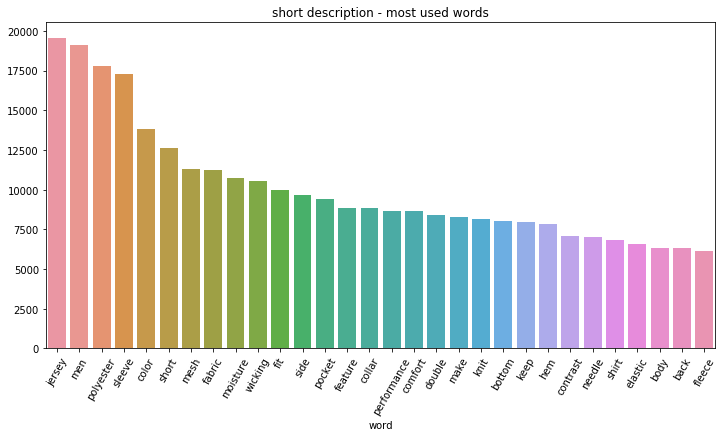

In [38]:
plt.figure(figsize=(12,6))
plt.title('short description - most used words')
sns.barplot(shrt_des_vc.keys()[:30],shrt_des_vc.values[:30])
plt.xlabel('word')
plt.xticks(rotation=60)


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]),
 <a list of 30 Text xticklabel objects>)

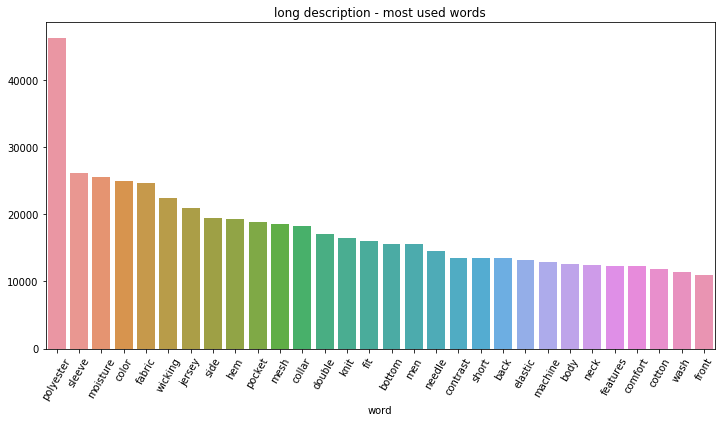

In [39]:
lng_des_vc = pd.value_counts(' '.join(catalogue_copy['clean_long_des'].values).split())
plt.figure(figsize=(12,6))
plt.title('long description - most used words')
sns.barplot(lng_des_vc.keys()[:30],lng_des_vc.values[:30])
plt.xlabel('word')
plt.xticks(rotation=60)

    Both short and long descriptions are about the cloth, quality, material... from the above graphs it is evident that without the presence of an obvious keyword(table, car etc.,) it is very difficult to say that a product does not belong to clothing
    Even though there are products other than clothing, it is clear they are not many in number because they didn't show up in the most used words

In [40]:
counts = Counter()
for desc in catalogue_copy['clean_sh_des']:
    words = desc.split()
    counts.update(ngrams(words,2))
counts.most_common(n=30)

[(('double', 'needle'), 6311),
 (('needle', 'hem'), 5318),
 (('moisture', 'wicking'), 4309),
 (('contrast', 'color'), 4294),
 (('short', 'sleeve'), 4151),
 (('moisture', 'away'), 3935),
 (('away', 'body'), 3892),
 (('wicks', 'moisture'), 3836),
 (('elastic', 'waistband'), 3731),
 (('polyester', 'wicking'), 3332),
 (('long', 'sleeve'), 2985),
 (('jersey', 'make'), 2931),
 (('cycling', 'jersey'), 2899),
 (('hem', 'sleeve'), 2880),
 (('self', 'fabric'), 2767),
 (('wicking', 'knit'), 2727),
 (('set', 'sleeve'), 2717),
 (('side', 'panel'), 2630),
 (('heat', 'seal'), 2431),
 (('polyester', 'spandex'), 2424),
 (('t', 'shirt'), 2404),
 (('xs', 'xl'), 2402),
 (('sizes', 'xs'), 2396),
 (('available', 'sizes'), 2349),
 (('hem', 'bottom'), 2266),
 (('comfort', 'feature'), 2220),
 (('sleeve', 'bottom'), 2217),
 (('seal', 'label'), 2213),
 (('feature', 'dye'), 2192),
 (('dye', 'process'), 2192)]

In [41]:
for i in wn.wordnet.synset('clothing.n.01').hyponyms():
    print(i, i.hyponyms())


Synset('accessory.n.01') [Synset('belt.n.02'), Synset('furnishing.n.01')]
Synset('apparel.n.01') [Synset('workwear.n.01')]
Synset('array.n.03') [Synset('war_paint.n.02')]
Synset('attire.n.01') [Synset('ao_dai.n.01'), Synset('costume.n.01'), Synset('costume.n.02'), Synset('costume.n.03'), Synset('costume.n.04'), Synset('disguise.n.02'), Synset('ecclesiastical_attire.n.01'), Synset('finery.n.01'), Synset('formalwear.n.01'), Synset('habit.n.03'), Synset('habit.n.05'), Synset('hairpiece.n.01'), Synset('morning_dress.n.01'), Synset('outfit.n.02'), Synset('sportswear.n.01')]
Synset('beachwear.n.01') []
Synset('black.n.07') []
Synset('blue.n.02') []
Synset('change.n.07') []
Synset('civilian_clothing.n.01') [Synset('civies.n.01'), Synset('mufti.n.02')]
Synset('drag.n.04') []
Synset('footwear.n.01') [Synset('hosiery.n.01')]
Synset('garment.n.01') [Synset('breechcloth.n.01'), Synset('burqa.n.01'), Synset('camlet.n.01'), Synset('diaper.n.01'), Synset('fur.n.03'), Synset('gown.n.04'), Synset('haik

In [42]:
hyponyms = wn.wordnet.synset('garment.n.01').hyponyms()
def garment_types():
    for ss,ind in zip(hyponyms,range(len(hyponyms))):
        lis = ss.hyponyms()
        if len(lis) != 0:
            for val in lis:
                yield(val.name())
        yield(ss.name())

In [43]:
garments = []
for name in garment_types():
    garments.append(name[:-5])

    We have stored all clothing types that fall under garments by going through all the hyponyms but it didn't give good results(after performing our predective operations), can you figure out why? hint: have a good look at the above hyponyms

    The garments list though promising couldn't perform well in our similarity function since there's a lot of clothing related information out of garments but under clothing.

In [44]:
ss_clothing = wn.wordnet.synset('clothing.n.01')
clothing = list()
def get_clothing_items(ss_clothing):
    for item in ss_clothing.hyponyms():
        try:
            get_clothing_items(item)
            clothing.append(item.name()[:-5])
        except:
            continue
    
    return clothing
        
for ss in wn.wordnet.synset('fabric.n.01').hyponyms():
    clothing.append(ss.name()[:-5])
    
clothing.append('fabric')
clothing_set = set(clothing)

    Now, we are also storing all words that fall under clothing and fabric to capture most of the information from clothing hyponyms. 

In [45]:
non_clothe = ['entity']
for ss in wn.wordnet.synset('entity.n.01').hyponyms():
    for inner_ss in ss.hyponyms():
        non_clothe.append(inner_ss.name()[:-5])

In [46]:
def get_similarity_dict(row):
    if row['clean_long_des'] != ' ':
        text = row['clean_long_des']
    elif row['clean_sh_des'] != ' ':
        text = row['clean_sh_des']
    elif row['clean_title'] != ' ':
        text = row['clean_title']
    
    clothe_words = set(text.split()).intersection(clothing_set)
    if len(clothe_words) == 0:
        return None
    
    #print(clothe_words)
    only_nouns = []
    for word,tag in pos_tag(text.split()):
        if (tag.startswith('N')):
            only_nouns.append(word)
    #print(only_nouns)
    
    similarity_dict = {}
    for ngram in ngrams(only_nouns,4):
        ngram_set = set(ngram)
        ints = ngram_set.intersection(clothing_set)
        if len(ints) > 0:
            word = ints.pop()
            for gram in ngram:
                if gram != word:
                    key = str(word)+'_'+str(gram)
                    for ss in wn.wordnet.synsets(word):
                        ss_name = ss.name()
                        
                        for ss2 in wn.wordnet.synsets(gram):
                            try:
                                #print(gram)
                                hypernym = ss.lowest_common_hypernyms(ss2)
                                sim = wn.wordnet.path_similarity(ss,ss2)
                                #print(hypernym, sim)
                                if key in similarity_dict.keys() and (similarity_dict[key][1]<sim):
                                    similarity_dict[key] = [hypernym[0].name()[:-5],sim]
                                    #similarity_dict[key] = [hypernym,sim]
                                elif key not in similarity_dict.keys():
                                    similarity_dict[key] = [hypernym[0].name()[:-5],sim]
                                    #similarity_dict[key] = [hypernym,sim]
                                else:
                                    pass
            
                            except Exception as e:
                                #print(e)
                                continue
                
    try:
        similarity_dict_len = len(similarity_dict)
        clothe_words_len = len(clothe_words)
        if similarity_dict_len == 0:
            return clothe_words_len/len(text.split())
        entities = [value[0] for value in similarity_dict.values() if value[0] in non_clothe or 'entity' in value[0]]
        entity_len = len(entities)
        non_clothing_chance = entity_len/similarity_dict_len
        clothing_chance = 1 - non_clothing_chance
    
        return clothing_chance #,similarity_dict
    
    except ZeroDivisionError as err:
        
        return clothe_words_len/(len(text.split())-clothe_words_len)
    
    


    You must be wondering, we have anyway created lists for clothing related words why not just count the number of words from description that fall in this category, normalize it with total length and define a probability? Why can't we do that?

    This surely works when we are not interested in the relation/ effect a word has on it's neighboring words. So, we calculate effect on each clothe word by the neighbors to understand it's cluster.
    
*example: "wooden baseball jersey display case"* 

    Jersey is clearly a clothe but the product here is the display case, and we know it only when the effect of it's neighbors is considered

In [47]:
all_pred = catalogue_copy.apply(get_similarity_dict,axis=1)

In [48]:
sum(all_pred>0.5)

42192

In [49]:
all_pred_title = catalogue_copy.apply(get_similarity_dict,axis=1)

In [50]:
sum(all_pred_title>=0.5)

43979

    Our formula thinks only 44162 descriptions qualify as clothing products at a threshold of 0.5. On checking randomly, to a certain extent that is true becuase many of the product's descriptions have nouns that do not resemble clothe words in turn rendering the formula not very useful to calculate similarity
    
    On the other hand when we used only titles to classify, formula shows 18859 products as clothing or related items at 0.5 threshold. This is far worse than that for descriptions. This observation makes sense: more the text we have, better the chances of finding all clues that represent clothing and vice versa.
   
#### Intention
    We have took the pain of creating a formula without using machine's intelligence to show how powerful wordnet is. Since this is an unsupervised problem, there is no saying how well data is clustered and that was not the original intent to use wordnet. Creating the chances of a product belonging to clothing is like a catalyst for more of our powerful algorithms. Hence forth, we will include this feature in modeling

In [51]:
catalogue_copy['clothing_chance'] = all_pred
catalogue_copy['clothing_chance'] = catalogue_copy['clothing_chance'].apply(lambda val: round(val,2))

In [46]:
def extract_basic_features(row):
    if row['long_description'] != ' ':
        text = row['long_description']
    elif row['short_description'] != ' ':
        text = row['short_description']
    else:
        text = row['title']
        
    tokens = text.split(' ')
    word_count = len(tokens)
    numeric_count = len(re.findall('[0-9]+\.[0-9]+|[0-9]+',text))
    punct_count = len(re.findall('\W+',re.sub(' ','',text)))
    clothe_words = [word for word in text.split() if word in clothing_set]
    clothe_words_len = len(clothe_words)
    noun_count = len([word for word,tag in pos_tag(text.split()) if tag.startswith('N')])
    
    return word_count,numeric_count,punct_count,clothe_words,clothe_words_len,noun_count

In [47]:
catalogue_copy[['word_count','numeric_count','punct_count','clothe_words','clothe_words_len','noun_count']] = catalogue_copy.apply(extract_basic_features,axis=1,result_type='expand')

In [54]:
catalogue_copy.head()

,product_id,root_node,title,shelf,outlier,item_id,short_description,long_description,all_shelves,first_shelf?,clean_title,clean_sh_des,clean_long_des,clothing_chance,word_count,numeric_count,punct_count,clothe_words,clothe_words_len,noun_count
0,642E2J75K4EE,Clothing,Men's Performance Penn State University Gridlo...,Clothing/Men/Men's Activewear,1.0,155051843,Men's Performance Penn State University Gridl...,Men's Performance Penn State University Gridl...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True,men performance penn state university gridlock...,men performance penn state university gridlock...,men performance penn state university gridlock...,0.90,91,1,9,[print],1,47
1,36HSVAC1S3P1,Clothing,Faded Glory Men's Fleece Lined Flannel,Clothing/Men/Men's Jackets & Outerwear,1.0,45466849,This Faded Glory Men's Fleece Lined Flannel is...,Faded Glory Men's Fleece Lined Flannel : Sh...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",False,faded glory men fleece lined flannel,faded glory men fleece lined flannel perfect f...,faded glory men fleece lined flannel shell cot...,0.85,45,3,10,[],0,32
2,58EH09O2BBCY,Clothing,Hanes Mens Premium Beefy-T Cotton Long Sleeve ...,Clothing/Men/Men's Activewear,1.0,14710841,If you love our famous Beefy-T tee (and everyb...,Hanes Mens Premium Beefy-T Cotton Long Sleeve...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True,hanes mens premium beefy t cotton long sleeve ...,love famous beefy t tee everybody youll want w...,hanes mens premium beefy t cotton long sleeve ...,0.72,125,2,27,"[cotton, fabric, cotton, knit]",4,62
3,157YUJ985OVJ,Clothing,219 Wicking Color Block Jersey - Youth GOLD/WH...,Clothing/Men/Men's Activewear,1.0,171359926,100% polyester wicking knit with 93% polyester...,100% polyester wicking knit with 93% polyester...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True,wicking color block jersey youth gold white s,polyester wicking knit polyester spandex mesh ...,polyester wicking knit polyester spandex mesh ...,0.92,37,5,13,"[polyester, knit, spandex]",3,19
4,4QL7H4GISSG1,Clothing,Nike Men's Dri-Fit Tech Vent Stripe Golf Polo ...,Clothing/Men/Men's Activewear,1.0,184542132,Nike Men's Dri-Fit Tech Vent Stripe Golf Polo...,Nike Men's Dri-Fit Tech Vent Stripe Golf Polo...,"[{'shelf': 'Clothing/Men/Men's Activewear', 'v...",True,men dri fit tech vent stripe golf polo shirt,men dri fit tech vent stripe golf polo shirt r...,men dri fit tech vent stripe golf polo shirt f...,1.00,57,1,6,[],0,25


    We have created a very complex formula to help our model identify clothing products better, do we still need all the basic features?

#### For the sake of analysis, let's consider clothing_chance as the target

(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5]), <a list of 6 Text xticklabel objects>)

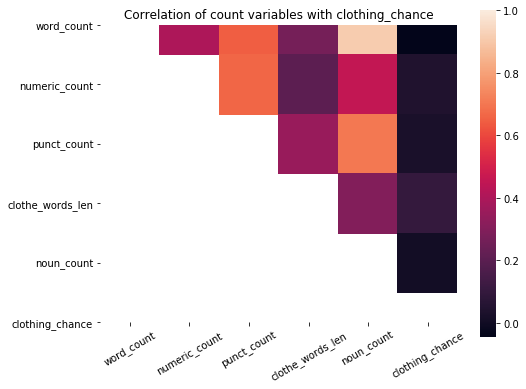

In [55]:
corr = catalogue_copy[['word_count','numeric_count','punct_count','clothe_words_len','noun_count','clothing_chance']].corr()
plt.figure(figsize=(8,6))
plt.title('Correlation of count variables with clothing_chance',fontsize=12)

mask = np.zeros_like(corr, dtype=np.bool)
mask[np.tril_indices_from(mask)] = True
sns.heatmap(corr,mask=mask,square=True,vmax=1)
plt.xticks(rotation=30)


    From the plot clothing_chance is the least correlated feature of all. The other pattern's are expected: all count variables are most correlated to number of words in text. Another interesting finding, punctuation and numeric counts are correlated decently. 

In [48]:
#Let's normalize all the count variables
catalogue_copy['norm_numeric_count'] = catalogue_copy['numeric_count'] / catalogue_copy['word_count']
catalogue_copy['norm_punct_count'] = catalogue_copy['punct_count'] / catalogue_copy['word_count']
catalogue_copy['norm_noun_count'] = catalogue_copy['noun_count'] / catalogue_copy['word_count']
catalogue_copy['norm_clothe_words_len'] = catalogue_copy['clothe_words_len'] / catalogue_copy['word_count']

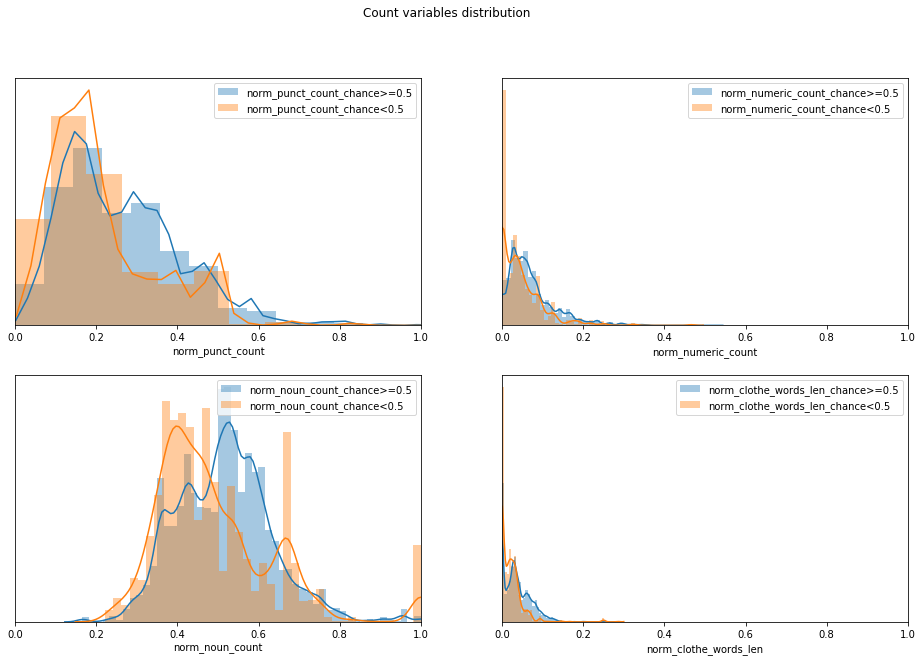

In [57]:
fig,ax = plt.subplots(2,2,figsize=(16,10))
fig.suptitle('Count variables distribution',fontsize=12)
ax = ax.flatten()
for a,var in zip(ax,['norm_punct_count','norm_numeric_count','norm_noun_count','norm_clothe_words_len']):
    sns.distplot(catalogue_copy[catalogue_copy['clothing_chance']>=0.5][var],ax=a,label=var+'_chance>=0.5')
    sns.distplot(catalogue_copy[catalogue_copy['clothing_chance']<0.5][var],ax=a,label=var+'_chance<0.5')
    a.set_xlim(0,1)
    a.set_yticks(ticks=[])
    a.legend()
    

    Which of the above features can we use in our model? why? why not?

    All variables follow pretty much expected pattern except for the norm_noun_count. We can see a clear peak at 0.4 for rows with chance less than 0.5 and at 0.58 for chance >= 0.5. Since there is an observable difference we can use it in our model.
    Also, norm_numeric_count could do good because we have seen products like display cases, and they come with measurements so there can be a peak in non_clothe products as confirmed by our graph above

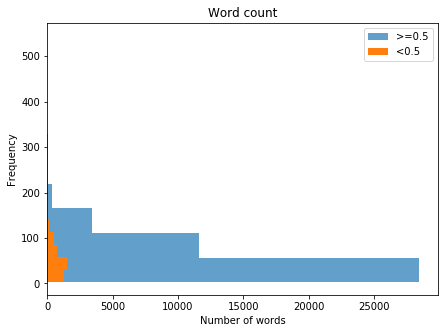

In [58]:
plt.figure(figsize=(7,5))
plt.hist(catalogue_copy[catalogue_copy['clothing_chance']>=0.5]['word_count'],orientation='horizontal',alpha=0.7,label='>=0.5')
plt.hist(catalogue_copy[catalogue_copy['clothing_chance']<0.5]['word_count'],orientation='horizontal',label='<0.5')
plt.title('Word count',fontsize=12)
plt.xlabel('Number of words')
plt.ylabel('Frequency')
plt.legend()

    There is a clear overlap but there is also a clear distinction in the number of words present in either categories. Hence this is a good feature for our model but after scaling.

In [50]:
wd_count = np.array(catalogue_copy['word_count'])
wd_count = wd_count.reshape(-1,1)
catalogue_copy['scaled_word_count'] = MinMaxScaler().fit_transform(wd_count)

In [60]:
def get_word_similarity_to_apparel(description):
    '''calculates similarity of each word to apparel and creates 2 lists one holding words with similarity to apparel
    greater than 20% and the other with similarity less than 20%'''
    similarity_cl = list()
    similarity_non_cl = list()
    for word,tag in pos_tag(description.split()):
        if tag.startswith('N') and len(word) > 1:
            try:
                temp = wv.similarity('apparel',word)
            except:
                continue
            if temp > 0.2:
                similarity_cl.append(temp)
                print(word,temp)
            else:
                similarity_non_cl.append(temp)
                print(word,temp) 
    print(np.sum(similarity_cl)-np.sum(similarity_non_cl))

In [61]:
get_word_similarity_to_apparel(catalogue_copy['clean_long_des'][3359])

length 0.030119507
inseam 0.24764769
panel 0.015084301
design 0.1804419
band 0.0395741
leg 0.089917734
grip 0.03951687
bib 0.26984668
stitch 0.14048624
construction 0.19672833
-0.2143746


    We have tried similarity of each word with 'apparel', was that a success?

    This is another experiment we performed to measure similarity of a given text to clothing. However, that was a successful failure. It was a failure because we couldn't gain value out of it but it was successful because we explored a new way to work with text

## Modeling

### TF-IDF

In [62]:
tfidf_vec = TfidfVectorizer(max_features=300,max_df=0.8)
tfidf_mat = tfidf_vec.fit_transform(catalogue_copy['clean_long_des'])

tfidf_names = tfidf_vec.get_feature_names()
tfidf_df = pd.DataFrame(tfidf_mat.todense().tolist(),columns=tfidf_names)


#remmember? we also decided to use few count features in our model. Let's add those to the tfidf
tfidf_df['scaled_word_count'] = catalogue_copy['scaled_word_count']
tfidf_df['norm_noun_count'] = catalogue_copy['norm_noun_count']
tfidf_df['norm_numeric_count'] = catalogue_copy['norm_numeric_count']

### DBSCAN

In [63]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN().fit(tfidf_df.to_numpy())

In [64]:
pd.value_counts(dbscan.labels_)

-1       4813
 76      1394
 14       967
 109      505
 89       505
         ... 
 1329       5
 1734       5
 1764       5
 1796       5
 1791       5
Length: 1806, dtype: int64

    DBSCAN believes 4777 instances are anomalies and overall it clustered the given data points to 1806 groups. Clearly this is not what we are expecting. Let's look at the -1 group and see if there's something interesting  

In [65]:
ind = np.where(dbscan.labels_ == -1)
catalogue_copy['clean_long_des'][ind[0]]
#apparently not a very useful group for our problem

34       styled full motion stretch thermal fabric rc p...
38       polyester wholesale discount cheap bulk lightw...
52       black realtree xtra polyester performance mate...
57       wpn features men raglan block top material pct...
63       year champion athleticwear outfit athlete auth...
                               ...                        
56357    michael jordan sign bulls red mitchell ness je...
56361    mcdavid classic logo cl hex pad mesh sleeveles...
56365    men dri fit flat front tech golf shorts featur...
56368    ordinary jacket ordinary golfer thankfully pro...
56396    polyester spandex bi ply fabric duofold expedi...
Name: clean_long_des, Length: 4813, dtype: object

### KMeans clustering

In [66]:
sil_score = []
x = tfidf_df.to_numpy()
for n in range(2,5):
    km = KMeans(n_clusters=n,verbose=2).fit(x)
    sil_score.append((n,silhouette_score(x,km.labels_)))

Initialization complete
start iteration
done sorting
end inner loop
Iteration 0, inertia 51586.163995432544
start iteration
done sorting
end inner loop
Iteration 1, inertia 51116.41840858974
start iteration
done sorting
end inner loop
Iteration 2, inertia 50966.54241150938
start iteration
done sorting
end inner loop
Iteration 3, inertia 50927.67216593359
start iteration
done sorting
end inner loop
Iteration 4, inertia 50915.50010355103
start iteration
done sorting
end inner loop
Iteration 5, inertia 50911.65373087197
start iteration
done sorting
end inner loop
Iteration 6, inertia 50910.793137913926
start iteration
done sorting
end inner loop
Iteration 7, inertia 50910.73889008576
start iteration
done sorting
end inner loop
Iteration 8, inertia 50910.73649202369
center shift 1.909453e-07 within tolerance 3.025447e-07
Initialization complete
start iteration
done sorting
end inner loop
Iteration 0, inertia 51146.13057681631
start iteration
done sorting
end inner loop
Iteration 1, inertia

Iteration 6, inertia 49634.28540180283
start iteration
done sorting
end inner loop
Iteration 7, inertia 49634.03026301038
start iteration
done sorting
end inner loop
Iteration 8, inertia 49633.453789123865
start iteration
done sorting
end inner loop
Iteration 9, inertia 49632.822480594376
start iteration
done sorting
end inner loop
Iteration 10, inertia 49632.746670174296
start iteration
done sorting
end inner loop
Iteration 11, inertia 49632.567884470154
start iteration
done sorting
end inner loop
Iteration 12, inertia 49632.56708161347
center shift 6.945786e-09 within tolerance 3.025447e-07
Initialization complete
start iteration
done sorting
end inner loop
Iteration 0, inertia 50971.02784884627
start iteration
done sorting
end inner loop
Iteration 1, inertia 50460.368394813835
start iteration
done sorting
end inner loop
Iteration 2, inertia 50291.82635833211
start iteration
done sorting
end inner loop
Iteration 3, inertia 50200.14487047004
start iteration
done sorting
end inner loop

Iteration 33, inertia 48240.55421830772
start iteration
done sorting
end inner loop
Iteration 34, inertia 48238.31546435659
start iteration
done sorting
end inner loop
Iteration 35, inertia 48234.97021113908
start iteration
done sorting
end inner loop
Iteration 36, inertia 48233.7701664288
start iteration
done sorting
end inner loop
Iteration 37, inertia 48233.677230563626
start iteration
done sorting
end inner loop
Iteration 38, inertia 48233.64885110154
start iteration
done sorting
end inner loop
Iteration 39, inertia 48233.64471245354
center shift 2.219192e-07 within tolerance 3.025447e-07
Initialization complete
start iteration
done sorting
end inner loop
Iteration 0, inertia 49384.92271467976
start iteration
done sorting
end inner loop
Iteration 1, inertia 48544.45411821977
start iteration
done sorting
end inner loop
Iteration 2, inertia 48245.21839705231
start iteration
done sorting
end inner loop
Iteration 3, inertia 48162.52470710863
start iteration
done sorting
end inner loop


Iteration 0, inertia 49840.78551411833
start iteration
done sorting
end inner loop
Iteration 1, inertia 48800.603651030826
start iteration
done sorting
end inner loop
Iteration 2, inertia 48438.440914568535
start iteration
done sorting
end inner loop
Iteration 3, inertia 48359.10182382151
start iteration
done sorting
end inner loop
Iteration 4, inertia 48310.2505247481
start iteration
done sorting
end inner loop
Iteration 5, inertia 48274.74245633004
start iteration
done sorting
end inner loop
Iteration 6, inertia 48258.26736929233
start iteration
done sorting
end inner loop
Iteration 7, inertia 48245.14082243687
start iteration
done sorting
end inner loop
Iteration 8, inertia 48239.3267521446
start iteration
done sorting
end inner loop
Iteration 9, inertia 48236.62751911869
start iteration
done sorting
end inner loop
Iteration 10, inertia 48234.7045298682
start iteration
done sorting
end inner loop
Iteration 11, inertia 48233.83953403772
start iteration
done sorting
end inner loop
Ite

Iteration 22, inertia 47146.75027136273
start iteration
done sorting
end inner loop
Iteration 23, inertia 47145.07658591117
start iteration
done sorting
end inner loop
Iteration 24, inertia 47144.204859453916
start iteration
done sorting
end inner loop
Iteration 25, inertia 47143.34462518734
start iteration
done sorting
end inner loop
Iteration 26, inertia 47143.15933232856
start iteration
done sorting
end inner loop
Iteration 27, inertia 47141.40594228188
start iteration
done sorting
end inner loop
Iteration 28, inertia 47138.99507919276
start iteration
done sorting
end inner loop
Iteration 29, inertia 47138.57536787363
start iteration
done sorting
end inner loop
Iteration 30, inertia 47138.03882141977
start iteration
done sorting
end inner loop
Iteration 31, inertia 47137.18494354956
start iteration
done sorting
end inner loop
Iteration 32, inertia 47136.30814898445
start iteration
done sorting
end inner loop
Iteration 33, inertia 47136.15823613038
start iteration
done sorting
end in

Iteration 1, inertia 47957.76851930846
start iteration
done sorting
end inner loop
Iteration 2, inertia 47572.612318557294
start iteration
done sorting
end inner loop
Iteration 3, inertia 47372.185519134815
start iteration
done sorting
end inner loop
Iteration 4, inertia 47198.32537320745
start iteration
done sorting
end inner loop
Iteration 5, inertia 47129.38238384466
start iteration
done sorting
end inner loop
Iteration 6, inertia 47104.25554397856
start iteration
done sorting
end inner loop
Iteration 7, inertia 47074.22310564158
start iteration
done sorting
end inner loop
Iteration 8, inertia 47049.95878096625
start iteration
done sorting
end inner loop
Iteration 9, inertia 47039.010143272615
start iteration
done sorting
end inner loop
Iteration 10, inertia 47036.35606139864
start iteration
done sorting
end inner loop
Iteration 11, inertia 47034.66115711735
start iteration
done sorting
end inner loop
Iteration 12, inertia 47033.58469091253
start iteration
done sorting
end inner loo

In [67]:
sil_score

[(2, 0.039815492674575875), (3, 0.04288585041180172), (4, 0.05562346754001029)]

    We can clearly see in the status of KMeans above that the inertia reduces as the number of clusters increase. However, if we would want the algorithm to predict the ideal number of clusters, then we can plot a graph with all the inertias and identify the elbow, that would be our optimum number of clusters.
    
    We can also use the silhouette_score to get a better picture of why the neighboring number of clusters of the elbow might also be good option for number of clusters
    
    Inertia: It is the sum of distance from each point in a cluster to the corresponding cluster center
    Silhouette score: (b-a)/max(a,b) where a is the mean distance of each instance to each of the other instances in the same cluster and b is the mean distance to the instances of the next nearest cluster

    Looks like our model believes there are more number of clusters than we originally thought but we know for a fact there are 2 clusters for sure and probably one more but more than that couldn't be considered right.
    
*Now, let's build the final KMeans model with 2 clusters*

In [68]:
catalogue_copy['KMeans_tfidf_300'] = KMeans(n_clusters=2,verbose=0).fit_predict(x)
pd.value_counts(catalogue_copy['KMeans_tfidf_300'])

0    42842
1    13556
Name: KMeans_tfidf_300, dtype: int64

    This performance is worse than our formula using wordnet. Can we try improving the model performance somehow?
    
    There are some things we could do differently for this model, let's try:
    tfidf with 500 features

In [51]:
#TFIDF with 500 features
tfidf_vec = TfidfVectorizer(max_features=500,max_df=0.8)
tfidf_mat = tfidf_vec.fit_transform(catalogue_copy['clean_long_des'])

tfidf_names = tfidf_vec.get_feature_names()
tfidf_df = pd.DataFrame(tfidf_mat.todense().tolist(),columns=tfidf_names)


#remmember? we also decided to use few count features in our model. Let's add those to the tfidf
tfidf_df['scaled_word_count'] = catalogue_copy['scaled_word_count']
tfidf_df['norm_noun_count'] = catalogue_copy['norm_noun_count']
tfidf_df['norm_numeric_count'] = catalogue_copy['norm_numeric_count']

In [70]:
#KMeans with 2 clusters
x = tfidf_df.to_numpy()
catalogue_copy['KMeans_tfidf_500'] = KMeans(n_clusters=2,verbose=0).fit_predict(x)
pd.value_counts(catalogue_copy['KMeans_tfidf_500'])

1    43778
0    12620
Name: KMeans_tfidf_500, dtype: int64

    This one's a little better than our previous model, there's actually a 10% increase in performance. How am I saying this? because our original data has an outlier column, though it is not an exact representation of the clusters, it is pretty clear that the number of non-clothing products are far lesser than clothing

In [52]:
x = tfidf_df.to_numpy()
iforest = IsolationForest(n_estimators=100,max_samples='auto',contamination=0.05).fit_predict(x)

In [53]:
pd.value_counts(iforest)

 1    53711
-1     2687
dtype: int64

In [54]:
np.where(iforest==-1)

(array([    9,    14,    20, ..., 56353, 56359, 56395]),)

In [57]:
catalogue_copy['long_description'][56359]

'5.3 oz., 91% polyester, 9% spandex body ; 4.7 oz., 91% polyester, 9% spandex pointelle mesh back panel; moisture-wicking and anti-microbial; cationic dyes to ensure superior brightness and excellent color fastness; athletic fit; self-fabric collar; self fabric Sport Graphite inner neck tape; three-button placket; self-fabric Sport Graphite inserts at shoulders;'

In [58]:
def sentence_average(row):
    if row['clean_long_des'] != '':
        text = row['clean_long_des']
    elif row['clean_sh_des'] != '':
        text = row['clean_sh_des']
    elif row['clean_title'] != '':
        text = row['clean_title']
    else:
        text = ' '
    
    if text != ' ':
        sentence_df = pd.DataFrame()
        for word,tag in pos_tag(text.split()):
            if tag.startswith('N') and len(word) > 1:
                try:
                    sentence_df = sentence_df.append(pd.Series(wv[word]),ignore_index=True)
                except:
                    continue

        return sentence_df.sum(axis=0)
    else:
        return pd.Series(data=np.zeros(300),index=[i for i in range(300)])

In [59]:
avg_wv = pd.DataFrame()
avg_wv = avg_wv.append(catalogue_copy.progress_apply(sentence_average,axis=1))

In [60]:
np.where(avg_wv.loc[:,0].isna())

(array([  675,  1323,  2273,  3702,  5375,  6277,  6816,  8905,  8911,
         9128,  9299,  9886, 11160, 13432, 14457, 15654, 17110, 17741,
        17953, 18137, 18221, 18474, 21004, 21262, 22068, 23341, 25054,
        25476, 26441, 26642, 27961, 28122, 28434, 28879, 31612, 31728,
        33271, 33640, 34525, 35108, 35204, 36164, 37156, 37336, 37679,
        38455, 38857, 38911, 39426, 39833, 40063, 43408, 45420, 52944,
        55462]),)

In [61]:
catalogue_copy['long_description'][1323]

'3500 3500.438.L'

    The above indices are not empty but they don't have any meaningful information as description as you can see in the example, so we can make all the vectors for these indieces 0
    
    POP QUIZ: What category should the above products be in?

    Well, we do not have any proof(like image) to be sure that the measurements are for clothes so I would expect them to be in non-clothing

In [76]:
#avg_wv_copy = avg_wv.copy(deep=True)
avg_wv.fillna(0,inplace=True)
x = avg_wv.to_numpy()
catalogue_copy['KMeans_wv'] = KMeans(n_clusters=2,verbose=0).fit_predict(x)
pd.value_counts(catalogue_copy['KMeans_wv'])

0    39354
1    17044
Name: KMeans_wv, dtype: int64

In [77]:
#Let's add the count features too
avg_wv['scaled_word_count'] = catalogue_copy['scaled_word_count']
avg_wv['norm_noun_count'] = catalogue_copy['norm_noun_count']
avg_wv['norm_numeric_count'] = catalogue_copy['norm_numeric_count']

In [69]:
#let's run our KMeans model with the new feature set again
x = avg_wv.to_numpy()
catalogue_copy['KMeans_wv_all_feat'] = KMeans(n_clusters=2,verbose=0).fit_predict(x)
pd.value_counts(catalogue_copy['KMeans_wv_all_feat'])

0    39354
1    17044
Name: KMeans_wv_all_feat, dtype: int64

    Adding the count features didn't make any difference to the wordvec data, it still stands where it previously did. Word2vec is a very powerful pretrained model, why do you think it didn't work well?

    word2vec is trained on the google news corpus, so it predominantly understands news with ease. Since our corpus here is clothing related, chances are comparitively less for great performance. 
    Let's look the isolation forest

In [62]:
avg_wv.fillna(0,inplace=True)
x = avg_wv.to_numpy()
iforest = IsolationForest(n_estimators=100,max_samples='auto',contamination=0.05).fit_predict(x)

In [63]:
pd.value_counts(iforest)

 1    53583
-1     2815
dtype: int64

    Isolation forest is an interesting approach, originally based on ensemble technique it creates various trees by sampling data, randomly picking a feature and setting a value between the min & max as a split criteria. When repeating these steps multiple times it takes a lot of levels to get to a normal data point but not so many for the anomalies.
    
    Anomaly_score = 2 ^ -(E(h(x))/c(n))
    where, h(x) is the path length of instance x
    c(n) is the average path length of an unsuccessful search in a binary search tree
    n is the number of datapoints in a choosen sample
    
    The problem with Isolationforest is we have to define a contamination percent that states a percent of our data that we believe is contaminated and the algorithm tries to find that many anomalies for us.

### Conclusion:
    The results we have gained till now are debatable especially with IsolationForest. However, when we don't have properly labeled data, the best thing to do is go with data understanding. We have seen that number of non-clothing items is of very low magnitude and hence we have selected 5% as threshold(you are invited to experiment with other thresholds).
    
    As always, this datatale isn't intended to give you a set in stone solution rather a swing at how to address problems related to text clustering. Yes! Yes! there can be more to be done, take the liberty to apply your ideas either as an extension or for the complete implementation.